# Lái xe tự động - Phát hiện xe hơi

Chào mừng bạn đến với bài tập lập trình của Tuần 3! Trong notebook này, bạn sẽ triển khai kỹ thuật phát hiện đối tượng sử dụng mô hình YOLO vô cùng mạnh mẽ. Nhiều ý tưởng trong notebook này được trình bày chi tiết trong hai bài báo nghiên cứu về YOLO: [Redmon và cộng sự, 2016](https://arxiv.org/abs/1506.02640) và [Redmon và Farhadi, 2016](https://arxiv.org/abs/1612.08242).

**Sau khi hoàn thành bài tập này, bạn sẽ có thể**:

- Phát hiện các đối tượng trong tập dữ liệu phát hiện xe hơi
- Triển khai thuật toán loại bỏ các hộp chồng lấp (non-max suppression) để tăng độ chính xác
- Triển khai tính toán chỉ số Intersection over Union (IoU - tỷ lệ phần giao trên phần hợp)
- Xử lý các hộp bao (bounding box) – một loại chú thích hình ảnh phổ biến trong học sâu (deep learning)

## Lưu ý quan trọng về việc nộp bài cho hệ thống chấm điểm tự động (AutoGrader)

Trước khi nộp bài tập cho hệ thống chấm điểm tự động, vui lòng đảm bảo bạn không thực hiện các hành động sau:

1. Thêm bất kỳ câu lệnh `print` *nào khác* vào bài tập.
2. Thêm bất kỳ ô mã nguồn (code cell) *nào khác* vào bài tập.
3. Thay đổi bất kỳ tham số nào của hàm.
4. Sử dụng biến toàn cục (global variable) bên trong các bài tập được chấm điểm. Trừ khi có hướng dẫn cụ thể, vui lòng tránh sử dụng biến toàn cục và thay vào đó hãy sử dụng biến cục bộ (local variable).
5. Thay đổi mã nguồn của bài tập ở những phần không yêu cầu, chẳng hạn như tạo thêm các biến *không cần thiết*.

Nếu thực hiện các hành động trên, bạn có thể gặp lỗi như `Grader not found` (hoặc các lỗi bất thường tương tự) khi nộp bài. Hãy kiểm tra các vấn đề này trước khi tìm kiếm sự trợ giúp hoặc gỡ lỗi (debug) cho bài tập của mình. Nếu bạn đã lỡ thay đổi và không nhớ rõ các thay đổi đó, bạn có thể lấy lại bản sao mới của bài tập bằng cách làm theo các [hướng dẫn này](https://www.coursera.org/learn/convolutional-neural-networks/supplement/DS4yP/h-ow-to-refresh-your-workspace).

## Table of Contents

- [Packages](#0)
- [1 - Problem Statement](#1)
- [2 - YOLO](#2)
    - [2.1 - Model Details](#2-1)
    - [2.2 - Filtering with a Threshold on Class Scores](#2-2)
        - [Exercise 1 - yolo_filter_boxes](#ex-1)
    - [2.3 - Non-max Suppression](#2-3)
        - [Exercise 2 - iou](#ex-2)
    - [2.4 - YOLO Non-max Suppression](#2-4)
        - [Exercise 3 - yolo_non_max_suppression](#ex-3)
    - [2.5 - Wrapping Up the Filtering](#2-5)
        - [Exercise 4 - yolo_eval](#ex-4)
- [3 - Test YOLO Pre-trained Model on Images](#3)
    - [3.1 - Defining Classes, Anchors and Image Shape](#3-1)
    - [3.2 - Loading a Pre-trained Model](#3-2)
    - [3.3 - Convert Output of the Model to Usable Bounding Box Tensors](#3-3)
    - [3.4 - Filtering Boxes](#3-4)
    - [3.5 - Run the YOLO on an Image](#3-5)
- [4 - Summary for YOLO](#4)
- [5 - References](#5)

<a name='0'></a>
## Packages

Run the following cell to load the packages and dependencies that will come in handy as you build the object detector!

In [1]:
import os
print(os.getcwd())
print(os.path.exists("yad2k/models/keras_yolo.py"))

/root/workspace/dls-c4/C4-Convolutional Neural Networks/week3/C4W3A1
True


In [2]:
import subprocess
import shutil
from pathlib import Path

repo = Path("/tmp/dls-yad2k")
source = "C4 - Convolutional Neural Networks/Week 3/Car detection for Autonomous Driving"

if not repo.exists():
    subprocess.run([
        "git", "clone", "--depth", "1",
        "--filter=blob:none", "--sparse",
        "https://github.com/amanchadha/coursera-deep-learning-specialization.git",
        str(repo)
    ], check=True)

subprocess.run([
    "git", "-C", str(repo),
    "sparse-checkout", "set", f"{source}/yad2k"
], check=True)

shutil.copytree(
    repo / source / "yad2k",
    Path.cwd() / "yad2k",
    dirs_exist_ok=True
)

print("Installed:", Path("yad2k/models/keras_yolo.py").exists())

Installed: True


In [3]:
import argparse
import os
import matplotlib.pyplot as plt
from matplotlib.pyplot import imshow
import scipy.io
import scipy.misc
import numpy as np
import pandas as pd
import PIL
from PIL import ImageFont, ImageDraw, Image
import tensorflow as tf
from tensorflow.python.framework.ops import EagerTensor

from tensorflow.keras.models import load_model
from yad2k.models.keras_yolo import yolo_head
from yad2k.utils.utils import draw_boxes, get_colors_for_classes, scale_boxes, read_classes, read_anchors, preprocess_image

%matplotlib inline

/tmp/ipykernel_3770527/1613439058.py:6: DeprecationWarning: scipy.misc is deprecated and will be removed in 2.0.0
  import scipy.misc
I0000 00:00:1791917987.611702 3770527 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


<a name='1'></a>
## 1 - Mô tả bài toán

Bạn đang thực hiện dự án phát triển xe tự lái. Thật tuyệt vời! Là một phần quan trọng của dự án này, trước tiên bạn cần xây dựng một hệ thống phát hiện xe hơi. Để thu thập dữ liệu, bạn đã gắn một camera lên nắp ca-pô (phần đầu xe); camera này sẽ chụp ảnh con đường phía trước vài giây một lần trong quá trình xe di chuyển.

<center>
<video width="400" height="200" src="nb_images/road_video_compressed2.mp4" type="video/mp4" controls>
</video>
</center>

<caption><center> Hình ảnh được chụp từ camera gắn trên xe khi di chuyển quanh Thung lũng Silicon. <br> Bộ dữ liệu được cung cấp bởi <a href="https://www.drive.ai/">drive.ai</a>.
</center></caption>

Bạn đã tập hợp tất cả các hình ảnh này vào một thư mục và gán nhãn bằng cách vẽ các khung bao (bounding box) quanh mỗi chiếc xe phát hiện được. Dưới đây là ví dụ về hình dạng của các khung bao này:

<img src="nb_images/box_label.png" style="width:500px;height:250;">
<caption><center> <u><b>Hình 1</u></b>: Định nghĩa về một khung bao<br> </center></caption>

Nếu có 80 lớp (class) mà bạn muốn hệ thống phát hiện đối tượng nhận diện, bạn có thể biểu diễn nhãn lớp $c$ dưới dạng một số nguyên từ 1 đến 80, hoặc dưới dạng một vectơ 80 chiều (gồm 80 số), trong đó có một thành phần bằng 1 và các thành phần còn lại bằng 0. Các bài giảng video đã sử dụng cách biểu diễn thứ hai; trong notebook này, bạn sẽ sử dụng cả hai cách biểu diễn tùy thuộc vào việc cách nào thuận tiện hơn cho từng bước cụ thể.

Trong bài tập này, bạn sẽ tìm hiểu cách YOLO ("You Only Look Once" - Bạn chỉ nhìn một lần) thực hiện việc phát hiện đối tượng, sau đó áp dụng nó vào bài toán phát hiện xe hơi. Do mô hình YOLO đòi hỏi chi phí tính toán rất lớn để huấn luyện, nên các trọng số đã được huấn luyện sẵn (pre-trained weights) sẽ được nạp vào để bạn sử dụng.

<a name='2'></a>
## 2 - YOLO

"You Only Look Once" (YOLO) là một thuật toán phổ biến nhờ khả năng đạt độ chính xác cao đồng thời hoạt động được trong thời gian thực. Thuật toán này "chỉ nhìn một lần" vào hình ảnh theo nghĩa là nó chỉ cần một lượt lan truyền xuôi (forward propagation) qua mạng để đưa ra dự đoán. Sau bước loại bỏ các hộp chồng lấp (non-max suppression), nó sẽ xuất ra các đối tượng được nhận diện cùng với các khung bao (bounding box).

<a name='2-1'></a>
### 2.1 - Chi tiết về mô hình

#### Đầu vào và đầu ra
- **Đầu vào** là một lô (batch) hình ảnh, và mỗi hình ảnh có kích thước (m, 608, 608, 3).
- **Đầu ra** là danh sách các khung bao cùng với các lớp (class) được nhận diện. Mỗi khung bao được biểu diễn bằng 6 số $(p_c, b_x, b_y, b_h, b_w, c)$ như đã giải thích ở trên. Nếu mở rộng $c$ thành một vectơ 80 chiều, thì mỗi khung bao sẽ được biểu diễn bằng 85 số.

#### Anchor Box (Khung neo)
* Các anchor box được chọn bằng cách khảo sát dữ liệu huấn luyện để xác định các tỷ lệ chiều cao/chiều rộng hợp lý, đại diện cho các lớp khác nhau. Trong bài tập này, 5 anchor box đã được chọn sẵn cho bạn (để bao phủ 80 lớp) và được lưu trong tệp './model_data/yolo_anchors.txt'.
* Kích thước của tensor mã hóa (dựa trên các anchor box) có dạng $(m, n_H, n_W, anchors, classes)$.
* Kiến trúc YOLO là: IMAGE (m, 608, 608, 3) -> DEEP CNN -> ENCODING (m, 19, 19, 5, 85).

#### Mã hóa (Encoding)
Hãy cùng xem xét chi tiết hơn về ý nghĩa của phần mã hóa này. <img src="nb_images/architecture.png" style="width:700px;height:400;">
<caption><center> <u><b> Hình 2 </u></b>: Kiến trúc mã hóa của YOLO<br> </center></caption>

Nếu tâm hoặc điểm giữa của một đối tượng rơi vào một ô lưới, thì ô lưới đó sẽ chịu trách nhiệm phát hiện đối tượng đó.

Vì bạn đang sử dụng 5 anchor box, nên mỗi ô trong lưới 19x19 sẽ mã hóa thông tin về 5 hộp này. Các anchor box được xác định chỉ dựa trên chiều rộng và chiều cao của chúng.

Để đơn giản hóa, bạn sẽ làm phẳng (flatten) hai chiều cuối cùng của cấu trúc dữ liệu mã hóa có dạng (19, 19, 5, 85), nhờ đó đầu ra của mạng Deep CNN sẽ có dạng (19, 19, 425).

<img src="nb_images/flatten.png" style="width:700px;height:400;">
<caption><center> <u><b> Hình 3 </u></b>: Làm phẳng hai chiều cuối cùng<br> </center></caption>

#### Điểm số lớp (Class score)

Bây giờ, với mỗi khung (thuộc mỗi ô lưới), bạn sẽ tính tích từng phần tử (element-wise product) sau đây và trích xuất xác suất khung đó chứa một lớp cụ thể.
Điểm số lớp là $score_{c,i} = p_{c} \times c_{i}$: xác suất có vật thể ($p_{c}$) nhân với xác suất vật thể đó thuộc một lớp cụ thể ($c_{i}$).

<img src="nb_images/probability_extraction.png" style="width:700px;height:400;">
<caption><center> <u><b>Hình 4</u></b>: Xác định lớp được phát hiện bởi mỗi khung<br> </center></caption>

##### Ví dụ về Hình 4
* Trong Hình 4, giả sử đối với khung 1 (ô 1), xác suất tồn tại vật thể là $p_{1}=0.60$. Nghĩa là có 60% khả năng tồn tại một vật thể trong khung 1 (ô 1).
* Xác suất vật thể đó thuộc lớp "loại 3 (ô tô)" là $c_{3}=0.73$.
* Điểm số cho khung 1 và loại "3" là $score_{1,3}=0.60 \times 0.73 = 0.44$.
* Giả sử bạn tính điểm số cho tất cả 80 lớp trong khung 1 và thấy rằng điểm số cho lớp ô tô (lớp 3) là cao nhất. Khi đó, bạn sẽ gán điểm số 0.44 và lớp "3" cho khung "1" này.

#### Trực quan hóa các lớp
Dưới đây là một cách để trực quan hóa những gì YOLO dự đoán trên một hình ảnh:

- Với mỗi ô trong lưới 19x19, hãy tìm giá trị lớn nhất của các điểm số xác suất (lấy giá trị lớn nhất trong số 80 lớp, với mỗi khung neo - anchor box - sẽ có một giá trị lớn nhất).
- Tô màu ô lưới đó dựa trên loại vật thể mà ô lưới đó xác định là có khả năng xuất hiện cao nhất. Việc thực hiện thao tác này tạo ra hình ảnh sau:

<img src="nb_images/proba_map.png" style="width:300px;height:300;">
<caption><center> <u><b>Hình 5</u></b>: Mỗi ô trong lưới 19x19 được tô màu dựa trên lớp có xác suất dự đoán cao nhất tại ô đó.<br> </center></caption>

Lưu ý rằng hình ảnh trực quan hóa này không phải là một phần cốt lõi của chính thuật toán YOLO trong quá trình đưa ra dự đoán; nó chỉ là một cách hay để hiển thị trực quan kết quả trung gian của thuật toán.

#### Trực quan hóa các khung bao (bounding boxes)
Một cách khác để trực quan hóa đầu ra của YOLO là vẽ các khung bao mà mô hình tạo ra. Kết quả thu được sẽ trông như thế này:

<img src="nb_images/anchor_map.png" style="width:200px;height:200;">
<caption><center> <u><b>Hình 6</u></b>: Mỗi ô lưới cung cấp 5 khung bao. Tổng cộng, mô hình dự đoán: 19x19x5 = 1805 khung bao chỉ sau một lần nhìn vào ảnh (một lần truyền xuôi qua mạng)! Các màu sắc khác nhau đại diện cho các lớp (class) khác nhau. <br> </center></caption>

#### Loại bỏ các khung không tối ưu (Non-Max suppression)
Trong hình trên, các khung được vẽ chỉ là những khung mà mô hình gán cho xác suất cao, nhưng số lượng khung vẫn còn quá nhiều. Bạn muốn giảm kết quả đầu ra của thuật toán xuống còn một số lượng nhỏ hơn nhiều các đối tượng được phát hiện.

Để làm điều này, bạn sẽ sử dụng kỹ thuật **non-max suppression** (loại bỏ các khung không tối ưu). Cụ thể, bạn sẽ thực hiện các bước sau:
- Loại bỏ các khung có điểm số thấp. Nghĩa là, khung đó không có độ tin cậy cao trong việc phát hiện một lớp, có thể do xác suất có đối tượng thấp hoặc xác suất của lớp cụ thể đó thấp.
- Chỉ chọn một khung duy nhất khi có nhiều khung chồng lấp lên nhau và cùng phát hiện một đối tượng.

<a name='2-2'></a>
### 2.2 - Lọc dựa trên ngưỡng điểm số lớp (Class Scores)

Trước tiên, bạn sẽ áp dụng bộ lọc dựa trên ngưỡng; nghĩa là bạn sẽ loại bỏ bất kỳ khung bao (box) nào có "điểm số" lớp thấp hơn ngưỡng đã chọn.

Mô hình cung cấp tổng cộng 19x19x5x85 giá trị, trong đó mỗi khung bao được mô tả bởi 85 giá trị. Việc sắp xếp lại tensor có kích thước (19, 19, 5, 85) (hoặc (19, 19, 425)) thành các biến sau đây sẽ thuận tiện hơn:
- `box_confidence`: tensor có hình dạng $(19, 19, 5, 1)$ chứa $p_c$ (xác suất tin cậy về sự hiện diện của vật thể) cho mỗi khung bao trong số 5 khung bao được dự đoán tại mỗi ô trong lưới 19x19.
- `boxes`: tensor có hình dạng $(19, 19, 5, 4)$ chứa tọa độ điểm giữa và kích thước $(b_x, b_y, b_h, b_w)$ cho mỗi khung bao trong số 5 khung bao tại mỗi ô.
- `box_class_probs`: tensor có hình dạng $(19, 19, 5, 80)$ chứa "xác suất lớp" $(c_1, c_2, ... c_{80})$ cho mỗi lớp trong số 80 lớp đối với mỗi khung bao trong số 5 khung bao tại mỗi ô.

<a name='ex-1'></a>
### Bài tập 1 - yolo_filter_boxes

Hãy triển khai hàm `yolo_filter_boxes()`.
1. Tính toán điểm số của khung bao bằng cách thực hiện phép nhân từng phần tử (elementwise product) như được mô tả trong Hình 4 ($p \times c$). Đoạn mã sau có thể giúp bạn chọn toán tử phù hợp:
```python
a = np.random.randn(19, 19, 5, 1)
b = np.random.randn(19, 19, 5, 80)
c = a * b # kích thước của c sẽ là (19, 19, 5, 80)
```
Đây là một ví dụ về **broadcasting** (nhân các vector có kích thước khác nhau).

2. Với mỗi khung (box), hãy tìm:
- chỉ số (index) của lớp có điểm số khung (box score) cao nhất
- điểm số khung tương ứng

**Tài liệu tham khảo hữu ích**
* [tf.math.argmax](https://www.tensorflow.org/api_docs/python/tf/math/argmax)
* [tf.math.reduce_max](https://www.tensorflow.org/api_docs/python/tf/math/reduce_max)

**Gợi ý hữu ích**
* Đối với tham số `axis` của `argmax` và `reduce_max`, nếu muốn chọn trục **cuối cùng**, bạn có thể đặt `axis=-1`. Cách này tương tự như việc đánh chỉ số mảng trong Python, nơi bạn có thể chọn vị trí cuối cùng của mảng bằng cách dùng `arrayname[-1]`. 
* Việc áp dụng `reduce_max` thường làm triệt tiêu (thu gọn) trục mà phép tính cực đại được thực hiện. `keepdims=False` là tùy chọn mặc định, cho phép loại bỏ chiều đó. Trong trường hợp này, bạn không cần giữ lại chiều cuối cùng sau khi tính giá trị cực đại.


3. Tạo một mặt nạ (mask) bằng cách sử dụng ngưỡng (threshold). Xin nhắc lại: `([0.9, 0.3, 0.4, 0.5, 0.1] < 0.4)` sẽ trả về kết quả: `[False, True, False, False, True]`. Mặt nạ cần có giá trị `True` đối với những khung mà bạn muốn giữ lại. 4. Sử dụng TensorFlow để áp dụng mặt nạ (mask) lên `box_class_scores`, `boxes` và `box_classes` nhằm loại bỏ các khung (box) không mong muốn. Kết quả thu được sẽ chỉ là tập hợp con các khung mà bạn muốn giữ lại. 

**Thêm một tài liệu tham khảo hữu ích**:
* [tf.boolean_mask](https://www.tensorflow.org/api_docs/python/tf/boolean_mask)

**Và thêm một gợi ý hữu ích nữa**: :)
* Đối với `tf.boolean_mask`, bạn có thể giữ nguyên giá trị mặc định `axis=None`.

In [4]:
def yolo_filter_boxes(boxes, box_confidence, box_class_probs, threshold = .6):
    """Lọc các khung hình (box) YOLO dựa trên ngưỡng (threshold) đối với độ tin cậy của đối tượng và lớp.

    Các tham số:
    boxes -- tensor có kích thước (19, 19, 5, 4) , 4 tọa độ của mỗi box
    box_confidence -- tensor có kích thước (19, 19, 5, 1) , 1 confidence cho mỗi box
    box_class_probs -- tensor có kích thước (19, 19, 5, 80) , Xác suất của 80 class cho mỗi box
    threshold -- giá trị thực; nếu [điểm xác suất lớp cao nhất < threshold], thì loại bỏ khung hình tương ứng

    Kết quả trả về:
    scores -- tensor có kích thước (None,), chứa điểm xác suất lớp của các khung hình được chọn
    boxes -- tensor có kích thước (None, 4), chứa tọa độ (b_x, b_y, b_h, b_w) của các khung hình được chọn
    classes -- tensor có kích thước (None,), chứa chỉ số (index) của lớp được phát hiện bởi các khung hình được chọn

    Lưu ý: Kích thước "None" được sử dụng vì ta không biết chính xác số lượng khung hình được chọn; con số này phụ thuộc vào giá trị ngưỡng.
    Ví dụ: Kích thước thực tế của tensor scores sẽ là (10,) nếu có 10 khung hình được chọn.
    """
    #Step 1: Tính điểm cho từng class của box
    
    box_scores = box_class_probs*box_confidence # Step 1: Tính score cho từng class của mỗi box
    
    #Tìm class và score lớn nhất của từng box
    box_classes = tf.math.argmax(box_scores , axis = -1) # Hàm này trả về index của class có score lớn nhất trong mỗi box.
    box_classes_scores = tf.math.reduce_max(box_scores , axis = -1) # Hàm này lấy giá trị score lớn nhất của mỗi box.
    #axis=-1 nghĩa là xét theo chiều cuối cùng, chính là chiều 80 class.
    
    #Step 3: Tạo mặt nạ lọc (filtering mask)
    filtering_mask = box_classes_scores >= threshold# Trả về giá trị True/False cho mỗi box.
    
    #Bước thực sự loại bỏ những box không đạt ngưỡng.
    scores = tf.boolean_mask(box_classes_scores , filtering_mask)
    boxes = tf.boolean_mask(boxes, filtering_mask)
    classes = tf.boolean_mask(box_classes, filtering_mask)
    
    return scores , boxes , classes

In [5]:
# BEGIN UNIT TEST
tf.random.set_seed(10)
box_confidence = tf.random.normal([19, 19, 5, 1], mean=1, stddev=4, seed = 1)
boxes = tf.random.normal([19, 19, 5, 4], mean=1, stddev=4, seed = 1)
box_class_probs = tf.random.normal([19, 19, 5, 80], mean=1, stddev=4, seed = 1)
scores, boxes, classes = yolo_filter_boxes(boxes, box_confidence, box_class_probs, threshold = 0.5)
print("scores[2] = " + str(scores[2].numpy()))
print("boxes[2] = " + str(boxes[2].numpy()))
print("classes[2] = " + str(classes[2].numpy()))
print("scores.shape = " + str(scores.shape))
print("boxes.shape = " + str(boxes.shape))
print("classes.shape = " + str(classes.shape))

assert type(scores) == EagerTensor, "Use tensorflow functions"
assert type(boxes) == EagerTensor, "Use tensorflow functions"
assert type(classes) == EagerTensor, "Use tensorflow functions"

assert scores.shape == (1789,), "Wrong shape in scores"
assert boxes.shape == (1789, 4), "Wrong shape in boxes"
assert classes.shape == (1789,), "Wrong shape in classes"

assert np.isclose(scores[2].numpy(), 9.270486), "Values are wrong on scores"
assert np.allclose(boxes[2].numpy(), [4.6399336, 3.2303846, 4.431282, -2.202031]), "Values are wrong on boxes"
assert classes[2].numpy() == 8, "Values are wrong on classes"

print("\033[92m All tests passed!")
# END UNIT TEST

scores[2] = 9.270486
boxes[2] = [ 4.639934   3.2303846  4.431282  -2.2020311]
classes[2] = 8
scores.shape = (1789,)
boxes.shape = (1789, 4)
classes.shape = (1789,)
 All tests passed!


I0000 00:00:1791917989.592935 3770527 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10101 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6


**Expected Output**:

<table>
    <tr>
        <td>
            <b>scores[2]</b>
        </td>
        <td>
           9.270486
        </td>
    </tr>
    <tr>
        <td>
            <b>boxes[2]</b>
        </td>
        <td>
           [ 4.6399336  3.2303846  4.431282  -2.202031 ]
        </td>
    </tr>
    <tr>
        <td>
            <b>classes[2]</b>
        </td>
        <td>
           8
        </td>
    </tr>
        <tr>
        <td>
            <b>scores.shape</b>
        </td>
        <td>
           (1789,)
        </td>
    </tr>
    <tr>
        <td>
            <b>boxes.shape</b>
        </td>
        <td>
           (1789, 4)
        </td>
    </tr>
    <tr>
        <td>
            <b>classes.shape</b>
        </td>
        <td>
           (1789,)
        </td>
    </tr>

</table>

**Lưu ý** Trong quá trình kiểm tra `yolo_filter_boxes`, bạn đang sử dụng các số ngẫu nhiên để kiểm tra hàm. Trong dữ liệu thực, `box_class_probs` sẽ chứa các giá trị khác 0 trong khoảng từ 0 đến 1 đối với xác suất. Tọa độ hộp trong `hộp` cũng sẽ được chọn sao cho chiều dài và chiều cao không âm.

<a name='2-3'></a>
### 2.3 - Loại bỏ các hộp không phải cực đại (Non-max Suppression)

Ngay cả sau khi lọc dựa trên ngưỡng điểm số lớp (class scores), bạn vẫn sẽ còn lại rất nhiều hộp chồng chéo lên nhau. Một bước lọc thứ hai để chọn ra các hộp chính xác được gọi là loại bỏ các hộp không phải cực đại (Non-max Suppression - NMS).

<img src="nb_images/non-max-suppression.png" style="width:500px;height:400;">
<caption><center> <u> <b>Hình 7</b> </u>: Trong ví dụ này, mô hình đã dự đoán có 3 chiếc xe, nhưng thực tế đó là 3 dự đoán cho cùng một chiếc xe. Việc áp dụng kỹ thuật loại bỏ các dự đoán không tối ưu (Non-Max Suppression - NMS) sẽ giúp chọn ra khung hình chính xác nhất (có xác suất cao nhất) trong số 3 khung hình này. <br> </center></caption>

Kỹ thuật loại bỏ các hộp dư thừa (Non-max suppression) sử dụng một hàm rất quan trọng có tên là **"Intersection over Union"** (tỷ lệ phần giao trên phần hợp), hay còn gọi là IoU.
<img src="nb_images/iou.png" style="width:500px;height:400;">
<caption><center> <u> <b>Hình 8</b> </u>: Định nghĩa về "Intersection over Union". <br> </center></caption>

<a name='ex-2'></a>
### Bài tập 2 - iou

Hãy cài đặt hàm `iou()`

Một số gợi ý:
- Đoạn mã này tuân theo quy ước: (0,0) là góc trên bên trái của ảnh, (1,0) là góc trên bên phải và (1,1) là góc dưới bên phải. Nói cách khác, gốc tọa độ (0,0) nằm ở góc trên bên trái của ảnh. Khi giá trị x tăng, bạn di chuyển sang phải. Khi giá trị y tăng, bạn di chuyển xuống dưới.
- Trong bài tập này, một hộp được xác định bởi hai góc: góc trên bên trái $(x_1, y_1)$ và góc dưới bên phải $(x_2, y_2)$, thay vì sử dụng tọa độ tâm, chiều cao và chiều rộng. Cách này giúp việc tính toán phần giao nhau trở nên dễ dàng hơn một chút.
- Để tính diện tích hình chữ nhật, hãy nhân chiều cao $(y_2 - y_1)$ với chiều rộng $(x_2 - x_1)$. Vì $(x_1, y_1)$ là góc trên bên trái còn $(x_2, y_2)$ là góc dưới bên phải, nên các hiệu số này sẽ không âm.
- Để tìm phần **giao nhau** của hai hộp $(xi_{1}, yi_{1}, xi_{2}, yi_{2})$:
- Bạn có thể vẽ một vài ví dụ ra giấy để hiểu rõ hơn về mặt khái niệm. 
- Góc trên bên trái của phần giao nhau $(xi_{1}, yi_{1})$ được xác định bằng cách so sánh các góc trên bên trái $(x_1, y_1)$ của hai hộp và tìm ra đỉnh có tọa độ x nằm xa hơn về phía bên phải (giá trị lớn hơn) và tọa độ y nằm xa hơn về phía dưới (giá trị lớn hơn). - Góc dưới bên phải của vùng giao nhau $(xi_{2}, yi_{2})$ được xác định bằng cách so sánh các góc dưới bên phải $(x_2, y_2)$ của hai hình chữ nhật và chọn ra đỉnh có tọa độ x nằm gần phía bên trái hơn, đồng thời có tọa độ y nằm gần phía trên hơn. 
- Hai hình chữ nhật **có thể không giao nhau**. Bạn có thể nhận biết điều này nếu các tọa độ giao nhau tính toán được lại chính là góc trên bên phải và/hoặc góc dưới bên trái của hình chữ nhật giao nhau. Một cách khác để hiểu vấn đề này là: nếu bạn tính chiều cao $(y_2 - y_1)$ hoặc chiều rộng $(x_2 - x_1)$ và thấy ít nhất một trong hai kích thước này mang giá trị âm, thì nghĩa là không có sự giao nhau (diện tích giao nhau bằng 0). 
- Hai hình chữ nhật có thể giao nhau tại **cạnh hoặc đỉnh**; trong trường hợp này, diện tích giao nhau vẫn bằng 0. Điều này xảy ra khi chiều cao hoặc chiều rộng (hoặc cả hai) của vùng giao nhau tính toán được bằng 0.


**Gợi ý bổ sung**

- `xi1` = giá trị **lớn nhất** (max) trong các tọa độ x1 của hai hình chữ nhật
- `yi1` = giá trị **lớn nhất** (max) trong các tọa độ y1 của hai hình chữ nhật
- `xi2` = giá trị **nhỏ nhất** (min) trong các tọa độ x2 của hai hình chữ nhật
- `yi2` = giá trị **nhỏ nhất** (min) trong các tọa độ y2 của hai hình chữ nhật
- `inter_area` = Bạn có thể sử dụng `max(height, 0)` và `max(width, 0)`

In [6]:
def iou(box1, box2) :
    #Khi tính diện tích một Box, ta giả định x2 > x1, y2 > y1
    """Triển khai tính toán Intersection over Union (IoU) giữa box1 và box2

    Các tham số:
    box1 -- hộp thứ nhất, đối tượng dạng danh sách chứa các tọa độ (box1_x1, box1_y1, box1_x2, box1_y2)
    box2 -- hộp thứ hai, đối tượng dạng danh sách chứa các tọa độ (box2_x1, box2_y1, box2_x2, box2_y2)
    """
    (box1_x1, box1_y1, box1_x2, box1_y2) = box1
    (box2_x1, box2_y1, box2_x2, box2_y2) = box2
    ### BẮT ĐẦU MÃ TẠI ĐÂY
    # Tính toán tọa độ (yi1, xi1, yi2, xi2) của phần giao nhau giữa box1 và box2. Tính diện tích của phần này. 
    ##(≈ 7 dòng)
    xi1 = max(box1_x1 , box2_x1)
    yi1 = max(box1_y1 , box2_y1)
    xi2 = min(box1_x2 , box2_x2)
    yi2 = min(box1_y2,box2_y2)
    inter_width = max(0,xi2-xi1)
    inter_height = max(0,yi2 - yi1)
    inter_area = inter_height * inter_width
    
    # Tính diện tích hợp bằng cách sử dụng công thức: Union(A,B) = A + B - Inter(A,B)
    box1_area = (box1_x2 - box1_x1)*((box1_y2 - box1_y1))
    box2_area = (box2_x2 - box2_x1)*((box2_y2 - box2_y1))
    union_area = box1_area + box2_area - inter_area
    
    # compute the IoU
    iou = inter_area / union_area
    
    return iou

<a name='2-4'></a>
### 2.4 - Loại bỏ các hộp dư thừa (Non-max Suppression) trong YOLO

Bây giờ bạn đã sẵn sàng để triển khai thuật toán loại bỏ các hộp dư thừa (non-max suppression). Các bước chính bao gồm:
1. Chọn hộp có điểm số (score) cao nhất.
2. Tính toán độ chồng lấp (overlap) của hộp này với tất cả các hộp khác, và loại bỏ những hộp có độ chồng lấp đáng kể (iou >= `iou_threshold`).
3. Quay lại bước 1 và lặp lại quy trình cho đến khi không còn hộp nào có điểm số thấp hơn hộp vừa được chọn.

Quá trình này sẽ loại bỏ tất cả các hộp có độ chồng lấp lớn với các hộp đã được chọn. Chỉ những hộp "tốt nhất" được giữ lại.

<a name='ex-3'></a>
### Bài tập 3 - yolo_non_max_suppression

Triển khai hàm `yolo_non_max_suppression()` sử dụng TensorFlow. TensorFlow cung cấp sẵn hai hàm để thực hiện việc loại bỏ các hộp dư thừa (do đó bạn không cần phải sử dụng hàm `iou()` mà mình đã tự viết trước đó):

**Tài liệu tham khảo**:

- [tf.image.non_max_suppression()](https://www.tensorflow.org/api_docs/python/tf/image/non_max_suppression)
```
tf.image.non_max_suppression(
boxes,
scores,
max_output_size,
iou_threshold=0.5,
name=None
)
```
Lưu ý rằng trong phiên bản TensorFlow được sử dụng ở đây, không có tham số `score_threshold` (tham số này chỉ xuất hiện trong tài liệu của phiên bản mới nhất), vì vậy nếu cố gắng thiết lập giá trị này, bạn sẽ gặp lỗi: *got an unexpected keyword argument `score_threshold`.*

- [tf.gather()](https://www.tensorflow.org/api_docs/python/tf/gather)
```
keras.gather(
reference,
indices
)
```

In [7]:
def yolo_non_max_suppression(scores, boxes, classes, max_boxes = 10, iou_threshold = 0.5):
    #Mục tiêu là tránh việc cùng một đối tượng bị phát hiện nhiều lần.
    """
    Áp dụng kỹ thuật Non-max suppression (NMS) cho tập hợp các khung (boxes)

    Các tham số:
    scores -- tensor có kích thước (None,), đầu ra của hàm yolo_filter_boxes().Điểm dự đoán của từng Box (. Điểm tin cậy của N box)
    boxes -- tensor có kích thước (None, 4), đầu ra của hàm yolo_filter_boxes() đã được điều chỉnh tỷ lệ theo kích thước ảnh (xem chi tiết sau).Tọa độ 4 giá trị  của từng Bounding Box
    classes -- tensor có kích thước (None,), đầu ra của hàm yolo_filter_boxes().Lớp đối tượng được dự đoán(Class được dự đoán cho từng box)
    max_boxes -- số nguyên, số lượng khung dự đoán tối đa mong muốn.Số lượng Box tối đa được giữ
    iou_threshold -- giá trị thực, ngưỡng "intersection over union" (giao trên hợp) được sử dụng để lọc bằng NMS.Ngưỡng IoU để loại Box trùng

    Giá trị trả về:
    scores -- tensor có kích thước (None,), điểm số dự đoán cho mỗi khung
    boxes -- tensor có kích thước (None, 4), tọa độ của các khung dự đoán
    classes -- tensor có kích thước (None,), lớp (class) dự đoán cho mỗi khung

    Lưu ý: Kích thước "None" của các tensor đầu ra chắc chắn phải nhỏ hơn max_boxes. Cũng cần lưu ý rằng
    hàm này sẽ chuyển vị (transpose) kích thước của scores, boxes và classes. Việc này được thực hiện nhằm mục đích thuận tiện.
    """
    max_boxes_tensor = tf.Variable(max_boxes , dtype = 'int32')#Tạo Tensor chứa số lượng box tối đa
    ### BẮT ĐẦU MÃ TẠI ĐÂY
    # Sử dụng tf.image.non_max_suppression() để lấy danh sách các chỉ số tương ứng với các khung được giữ lại
    ##(≈ 1 dòng)
    nms_indices = tf.image.non_max_suppression(boxes , scores , max_boxes_tensor , iou_threshold)
    #tf.image.non_max_suppression(): Chọn index của box có score lớn nhất, giữ lại rồi so sánh IoU với các box còn lại để loại những box có IoU vượt ngưỡng.
    #Tiếp tục chọn box có score lớn nhất trong số còn lại, lặp đến khi hết box hoặc đạt max_boxes, rồi trả về các index được giữ (nms_indices).
    #NMS dùng để loại các box dự đoán trùng lặp. Hàm NMS hiện tại chỉ xét score và IoU, không phân biệt class; muốn tránh loại box khác class thì cần áp dụng NMS riêng cho từng class.
    
    #Hàm tf.gather() trong TensorFlow dùng để trích xuất (lấy) các phần tử hoặc các lát cắt dữ liệu từ một Tensor dựa trên các chỉ số (indices) cho trước.
    scores = tf.gather(scores , nms_indices)
    boxes = tf.gather(boxes,nms_indices)
    classes = tf.gather(classes,nms_indices)
    ### END CODE HERE

    
    return scores, boxes, classes

In [8]:
# BEGIN UNIT TEST
tf.random.set_seed(10)
scores = tf.random.normal([54,], mean=1, stddev=4, seed = 1)
boxes = tf.random.normal([54, 4], mean=1, stddev=4, seed = 1)
classes = tf.random.normal([54,], mean=1, stddev=4, seed = 1)
scores, boxes, classes = yolo_non_max_suppression(scores, boxes, classes)

assert type(scores) == EagerTensor, "Use tensoflow functions"
print("scores[2] = " + str(scores[2].numpy()))
print("boxes[2] = " + str(boxes[2].numpy()))
print("classes[2] = " + str(classes[2].numpy()))
print("scores.shape = " + str(scores.numpy().shape))
print("boxes.shape = " + str(boxes.numpy().shape))
print("classes.shape = " + str(classes.numpy().shape))

assert type(scores) == EagerTensor, "Use tensoflow functions"
assert type(boxes) == EagerTensor, "Use tensoflow functions"
assert type(classes) == EagerTensor, "Use tensoflow functions"

assert scores.shape == (10,), "Wrong shape"
assert boxes.shape == (10, 4), "Wrong shape"
assert classes.shape == (10,), "Wrong shape"

assert np.isclose(scores[2].numpy(), 8.147684), "Wrong value on scores"
assert np.allclose(boxes[2].numpy(), [ 6.0797963, 3.743308, 1.3914018, -0.34089637]), "Wrong value on boxes"
assert np.isclose(classes[2].numpy(), 1.7079165), "Wrong value on classes"

print("\033[92m All tests passed!")
# END UNIT TEST

scores[2] = 8.147684
boxes[2] = [ 6.0797963   3.7433083   1.3914018  -0.34089637]
classes[2] = 1.7079165
scores.shape = (10,)
boxes.shape = (10, 4)
classes.shape = (10,)
 All tests passed!


**Expected Output**:

<table>
    <tr>
        <td>
            <b>scores[2]</b>
        </td>
        <td>
           8.147684
        </td>
    </tr>
    <tr>
        <td>
            <b>boxes[2]</b>
        </td>
        <td>
           [ 6.0797963   3.743308    1.3914018  -0.34089637]
        </td>
    </tr>
    <tr>
        <td>
            <b>classes[2]</b>
        </td>
        <td>
           1.7079165
        </td>
    </tr>
        <tr>
        <td>
            <b>scores.shape</b>
        </td>
        <td>
           (10,)
        </td>
    </tr>
    <tr>
        <td>
            <b>boxes.shape</b>
        </td>
        <td>
           (10, 4)
        </td>
    </tr>
    <tr>
        <td>
            <b>classes.shape</b>
        </td>
        <td>
           (10,)
        </td>
    </tr>

</table>

<a name='2-5'></a>
### 2.5 - Hoàn thiện quy trình lọc

Đã đến lúc triển khai một hàm nhận đầu ra từ mạng CNN sâu (mã hóa có kích thước 19x19x5x85) và lọc qua tất cả các khung hình (boxes) bằng cách sử dụng các hàm mà bạn vừa triển khai.

<a name='ex-4'></a>
### Bài tập 4 - yolo_eval

Hãy triển khai hàm `yolo_eval()`; hàm này nhận đầu ra từ quá trình mã hóa YOLO và lọc các khung hình dựa trên ngưỡng điểm số (score threshold) và thuật toán NMS. Có một chi tiết triển khai cuối cùng mà bạn cần lưu ý. Có nhiều cách biểu diễn khung hình, chẳng hạn như thông qua các tọa độ góc hoặc thông qua tọa độ điểm giữa kết hợp với chiều cao/chiều rộng. YOLO chuyển đổi giữa các định dạng này tại những thời điểm khác nhau bằng cách sử dụng các hàm sau (đã được cung cấp sẵn):

```python
boxes = yolo_boxes_to_corners(box_xy, box_wh)
```
hàm này chuyển đổi tọa độ khung hình YOLO (x, y, w, h) thành tọa độ các góc của khung hình (x1, y1, x2, y2) để phù hợp với đầu vào của hàm `yolo_filter_boxes`
```python
boxes = scale_boxes(boxes, image_shape)
```
Mạng YOLO được huấn luyện để hoạt động trên các hình ảnh có kích thước 608x608. Nếu bạn kiểm thử dữ liệu trên hình ảnh có kích thước khác — ví dụ: tập dữ liệu phát hiện xe hơi có các hình ảnh kích thước 720x1280 — thì bước này sẽ thay đổi tỷ lệ (rescale) các khung hình để chúng có thể được vẽ đè lên hình ảnh gốc kích thước 720x1280.

Đừng lo lắng về hai hàm này; bạn sẽ thấy vị trí cần gọi chúng ở phần dưới đây.

In [10]:
#yolo_boxes_to_corners() chuyển tọa độ từ tâm và kích thước sang hai góc đối diện để thuận tiện tính IoU và sử dụng NMS, không làm thay đổi vị trí hay kích thước thực tế của box.
def yolo_boxes_to_corners(box_xy,box_wh):
    box_mins = box_xy - (box_wh /2.)
    box_maxes = box_xy + (box_wh / 2.)
    return tf.keras.backend.concatenate([
        box_mins[..., 1:2],  # y_min
        box_mins[..., 0:1],  # x_min
        box_maxes[..., 1:2],  # y_max
        box_maxes[..., 0:1]  # x_max
    ])

In [ ]:
def yolo_eval(yolo_outputs , image_shape = (720 , 1280) , max_boxes = 10 , score_threshold = .6 , iou_threshold = 0.5) :
    """
    Chuyển đổi đầu ra của quá trình mã hóa YOLO (gồm nhiều khung hình) thành các khung hình dự đoán kèm theo điểm số, tọa độ khung hình và lớp (class) tương ứng.

    Các tham số:
    yolo_outputs -- đầu ra của mô hình mã hóa (với kích thước ảnh là (608, 608, 3)), bao gồm 4 tensor:
    box_xy: tensor có kích thước (None, 19, 19, 5, 2)
    box_wh: tensor có kích thước (None, 19, 19, 5, 2)
    box_confidence: tensor có kích thước (None, 19, 19, 5, 1)
    box_class_probs: tensor có kích thước (None, 19, 19, 5, 80)
    image_shape -- tensor có kích thước (2,) chứa kích thước ảnh đầu vào; trong notebook này, ta sử dụng (608., 608.) (phải có kiểu dữ liệu float32)
    max_boxes -- số nguyên, số lượng khung hình dự đoán tối đa mong muốn
    score_threshold -- giá trị thực, nếu [điểm xác suất lớp cao nhất < ngưỡng], thì loại bỏ khung hình tương ứng
    iou_threshold -- giá trị thực, ngưỡng "intersection over union" (giao trên hợp) được sử dụng cho quá trình lọc NMS

    Giá trị trả về:
    scores -- tensor có kích thước (None, ), điểm số dự đoán cho mỗi khung hình
    boxes -- tensor có kích thước (None, 4), tọa độ của các khung hình dự đoán
    classes -- tensor có kích thước (None,), lớp dự đoán cho mỗi khung hình
    """
    ### BẮT ĐẦU MÃ TẠI ĐÂY
    # Lấy các đầu ra của mô hình YOLO (≈1 dòng)
    box_xy , box_wh , box_confidence , box_class_probs = yolo_outputs #Đây là những thứ mô hình yolo học được
    
    # Chuyển đổi các hộp để sẵn sàng cho các hàm lọc (chuyển đổi các hộp dạng box_xy và box_wh sang tọa độ các góc)
    boxes = yolo_boxes_to_corners(box_xy , box_wh) # Đưa về dạng này để có thể tính được IoU thay vì dùng tọa độ tâm
    
    
    # Sử dụng một trong các hàm bạn đã triển khai để thực hiện lọc theo điểm số (score-filtering) với ngưỡng score_threshold (≈1 dòng)
    scores, boxes, classes = yolo_filter_boxes(boxes, box_confidence, box_class_probs, score_threshold)

    # Quy đổi kích thước các khung về kích thước ảnh gốc. 
    boxes = scale_boxes(boxes, image_shape)


    # Sử dụng một trong các hàm bạn đã triển khai để thực hiện loại bỏ các khung dư thừa (non-max suppression) với
    # số lượng khung tối đa là max_boxes và ngưỡng iou_threshold (≈1 dòng)
    scores, boxes, classes = yolo_non_max_suppression(scores, boxes, classes, max_boxes, iou_threshold)
    ### KẾT THÚC PHẦN MÃ TẠI ĐÂY

    return scores, boxes, classes
    

In [12]:
tf.random.set_seed(10)
yolo_outputs = (tf.random.normal([19,19,5,2], mean = 1 ,stddev = 4, seed =1), # box_xy: Tọa độ tâm của box
                tf.random.normal([19, 19, 5, 2], mean=1, stddev=4, seed = 1),#box_wh: Chiều rộng và chiều cao
                tf.random.normal([19, 19, 5, 1], mean=1, stddev=4, seed = 1),#box_confidence: Độ tin cậy của box
                tf.random.normal([19, 19, 5, 80], mean=1, stddev=4, seed = 1))#box_class_probs: Xác suất của 80 class
scores , boxes , classes = yolo_eval(yolo_outputs)
print("scores[2] = " + str(scores[2].numpy()))
print("boxes[2] = " + str(boxes[2].numpy()))
print("classes[2] = " + str(classes[2].numpy()))
print("scores.shape = " + str(scores.numpy().shape))
print("boxes.shape = " + str(boxes.numpy().shape))
print("classes.shape = " + str(classes.numpy().shape))

assert type(scores) == EagerTensor, "Use tensoflow functions"
assert type(boxes) == EagerTensor, "Use tensoflow functions"
assert type(classes) == EagerTensor, "Use tensoflow functions"

assert scores.shape == (10,), "Wrong shape"
assert boxes.shape == (10, 4), "Wrong shape"
assert classes.shape == (10,), "Wrong shape"
    
assert np.isclose(scores[2].numpy(), 171.60194), "Wrong value on scores"
assert np.allclose(boxes[2].numpy(), [-1240.3483, -3212.5881, -645.78, 2024.3052]), "Wrong value on boxes"
assert np.isclose(classes[2].numpy(), 16), "Wrong value on classes"
    
print("\033[92m All tests passed!")


scores[2] = 171.60194
boxes[2] = [-1240.3481 -3212.588   -645.7799  2024.3053]
classes[2] = 16
scores.shape = (10,)
boxes.shape = (10, 4)
classes.shape = (10,)
 All tests passed!


**Expected Output**:

<table>
    <tr>
        <td>
            <b>scores[2]</b>
        </td>
        <td>
           171.60194
        </td>
    </tr>
    <tr>
        <td>
            <b>boxes[2]</b>
        </td>
        <td>
           [-1240.3483 -3212.5881  -645.78    2024.3052]
        </td>
    </tr>
    <tr>
        <td>
            <b>classes[2]</b>
        </td>
        <td>
           16
        </td>
    </tr> 
        <tr>
        <td>
            <b>scores.shape</b>
        </td>
        <td>
           (10,)
        </td>
    </tr>
    <tr>
        <td>
            <b>boxes.shape</b>
        </td>
        <td>
           (10, 4)
        </td>
    </tr>
    <tr>
        <td>
            <b>classes.shape</b>
        </td>
        <td>
           (10,)
        </td>
    </tr>

</table>

<a name='3'></a>
## 3 - Kiểm thử mô hình YOLO đã được huấn luyện trước trên hình ảnh

Trong phần này, bạn sẽ sử dụng một mô hình đã được huấn luyện trước và kiểm thử nó trên tập dữ liệu phát hiện xe hơi.

<a name='3-1'></a>
### 3.1 - Định nghĩa các lớp, khung neo (anchor) và kích thước ảnh

Bạn đang thực hiện phát hiện 80 lớp đối tượng và sử dụng 5 khung neo (anchor box). Thông tin về 80 lớp và 5 khung neo này được lưu trữ trong hai tệp: "coco_classes.txt" và "yolo_anchors.txt". Bạn sẽ đọc tên các lớp và thông số khung neo từ các tệp văn bản này. Tập dữ liệu phát hiện xe hơi bao gồm các hình ảnh có kích thước 720x1280, vốn đã được tiền xử lý thành kích thước 608x608.

In [14]:
from pathlib import Path

anchors_path = Path("model_data/yolo_anchors.txt")

anchors_path.write_text(
    "0.57273,0.677385,"
    "1.87446,2.06253,"
    "3.33843,5.47434,"
    "7.88282,3.52778,"
    "9.77052,9.16828"
)

80

In [15]:
class_names = read_classes("model_data/coco_classes.txt")
anchors = read_anchors("model_data/yolo_anchors.txt")
model_image_size = (608, 608)

print(anchors)
print(anchors.shape)

[[0.57273  0.677385]
 [1.87446  2.06253 ]
 [3.33843  5.47434 ]
 [7.88282  3.52778 ]
 [9.77052  9.16828 ]]
(5, 2)


<a name='3-2'></a>
### 3.2 - Tải mô hình đã được huấn luyện trước

Việc huấn luyện một mô hình YOLO tốn rất nhiều thời gian và đòi hỏi một tập dữ liệu khá lớn với các khung bao (bounding box) đã được gán nhãn cho nhiều loại đối tượng khác nhau. Bạn sẽ tải một mô hình YOLO (dùng Keras) đã được huấn luyện trước và lưu trong tệp "yolo.h5". Các trọng số này được lấy từ trang web chính thức của YOLO và đã được chuyển đổi bằng một hàm do Allan Zelener viết. Thông tin tham khảo được liệt kê ở cuối notebook này. Về mặt kỹ thuật, đây là các tham số của mô hình "YOLOv2", nhưng trong notebook này, chúng được gọi đơn giản là "YOLO".

Hãy chạy ô mã dưới đây để tải mô hình từ tệp này.

In [20]:
from keras.models import load_model
from convert_yolov2_darknet_to_keras3 import SpaceToDepth

yolo_model = load_model(
    "model_data/yolo.keras",
    compile=False
)

print(yolo_model.output_shape)

(None, 19, 19, 425)


In [21]:
yolo_model.summary()

Model: "yolov2_608_coco"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ yolo_input          │ (None, 608, 608,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ darknet_conv_0      │ (None, 608, 608,  │        864 │ yolo_input[0][0]  │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ darknet_bn_0        │ (None, 608, 608,  │        128 │ darknet_conv_0[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 608, 608,  │          0 │ darknet_bn_0[0][… │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 304, 304,  │          0 │ leaky_re_lu[0][0] │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ darknet_conv_2      │ (None, 304, 304,  │     18,432 │ max_pooling2d[0]… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ darknet_bn_2        │ (None, 304, 304,  │        256 │ darknet_conv_2[0… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 304, 304,  │          0 │ darknet_bn_2[0][… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 152, 152,  │          0 │ leaky_re_lu_1[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ darknet_conv_4      │ (None, 152, 152,  │     73,728 │ max_pooling2d_1[… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ darknet_bn_4        │ (None, 152, 152,  │        512 │ darknet_conv_4[0… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 152, 152,  │          0 │ darknet_bn_4[0][… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ darknet_conv_5      │ (None, 152, 152,  │      8,192 │ leaky_re_lu_2[0]… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ darknet_bn_5        │ (None, 152, 152,  │        256 │ darknet_conv_5[0… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 152, 152,  │          0 │ darknet_bn_5[0][… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ darknet_conv_6      │ (None, 152, 152,  │     73,728 │ leaky_re_lu_3[0]… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ darknet_bn_6        │ (None, 152, 152,  │        512 │ darknet_conv_6[0

 Total params: 50,983,561 (194.49 MB)

 Trainable params: 50,962,889 (194.41 MB)

 Non-trainable params: 20,672 (80.75 KB)

**Lưu ý**: Trên một số máy tính, bạn có thể thấy thông báo cảnh báo từ Keras. Đừng lo lắng nếu gặp trường hợp này – mọi thứ vẫn ổn!

**Nhắc nhở**: Mô hình này chuyển đổi một lô ảnh đầu vào đã qua xử lý (có kích thước: (m, 608, 608, 3)) thành một tensor có kích thước (m, 19, 19, 5, 85) như đã được giải thích trong Hình (2).

<a name='3-3'></a>
### 3.3 - Chuyển đổi đầu ra của mô hình thành các tensor hộp bao (bounding box) có thể sử dụng được

Đầu ra của `yolo_model` là một tensor có kích thước (m, 19, 19, 5, 85); tensor này cần trải qua quá trình xử lý và chuyển đổi không đơn giản. Bạn sẽ cần gọi hàm `yolo_head` để định dạng lại kết quả mã hóa thu được từ `yolo_model` thành dạng dữ liệu có thể hiểu và sử dụng được:

yolo_model_outputs = yolo_model(image_data)
yolo_outputs = yolo_head(yolo_model_outputs, anchors, len(class_names))
Biến `yolo_outputs` sẽ được xác định là một tập hợp gồm 4 tensor; bạn có thể sử dụng các tensor này làm đầu vào cho hàm `yolo_eval`. Nếu muốn tìm hiểu cách triển khai hàm `yolo_head`, bạn có thể xem định nghĩa hàm trong tệp `keras_yolo.py`. Tệp này nằm trong không gian làm việc của bạn tại đường dẫn: `yad2k/models/keras_yolo.py`.

<a name='3-4'></a>
### 3.4 - Lọc các khung (Filtering Boxes)

`yolo_outputs` cung cấp tất cả các khung được dự đoán bởi `yolo_model` theo đúng định dạng. Để thực hiện lọc và chỉ chọn ra những khung tốt nhất, bạn sẽ gọi hàm `yolo_eval` (hàm mà bạn đã triển khai trước đó) để thực hiện việc này:

out_scores, out_boxes, out_classes = yolo_eval(yolo_outputs, [image.size[1],  image.size[0]], 10, 0.3, 0.5)

<a name='3-5'></a>
### 3.5 - Chạy YOLO trên một hình ảnh

Hãy bắt đầu nào! Bạn sẽ tạo một đồ thị (graph) có thể được tóm tắt như sau:

`yolo_model.input` được đưa vào `yolo_model`. Mô hình này được sử dụng để tính toán đầu ra `yolo_model.output`.
`yolo_model.output` được xử lý bởi `yolo_head`, tạo ra `yolo_outputs`.
`yolo_outputs` đi qua một hàm lọc là `yolo_eval`. Hàm này trả về các kết quả dự đoán: `out_scores`, `out_boxes`, `out_classes`.

Chúng tôi đã triển khai hàm `predict(image_file)` giúp bạn; hàm này thực thi đồ thị (graph) để kiểm thử mô hình YOLO trên một hình ảnh và tính toán các giá trị `out_scores`, `out_boxes`, `out_classes`.

Đoạn mã dưới đây cũng sử dụng hàm sau:

image, image_data = preprocess_image("images/" + image_file, model_image_size = (608, 608))
Hàm này thực hiện mở tệp hình ảnh, đồng thời thay đổi kích thước, định hình lại và chuẩn hóa hình ảnh. Nó trả về các kết quả sau:

image: một đối tượng Python (PIL) đại diện cho hình ảnh của bạn, được dùng để vẽ các khung bao (boxes). Bạn sẽ không cần sử dụng đến nó. 
image_data: một mảng numpy đại diện cho hình ảnh. Đây sẽ là dữ liệu đầu vào cho mạng CNN.

In [24]:
def predict(image_file):
    """

    Chạy đồ thị để dự đoán các hộp cho "image_file". In và vẽ biểu đồ các dự đoán.

    Tham số:

    image_file -- tên của một hình ảnh được lưu trữ trong thư mục "images".


    Trả về:

    out_scores -- tensor có hình dạng (None, ), điểm số của các hộp được dự đoán

    out_boxes -- tensor có hình dạng (None, 4), tọa độ của các hộp được dự đoán

    out_classes -- tensor có hình dạng (None, ), chỉ số lớp của các hộp được dự đoán

    Lưu ý: "None" thực sự đại diện cho số lượng hộp được dự đoán, nó thay đổi từ 0 đến max_boxes.

    """
    # Preprocess your image
    image, image_data = preprocess_image("images/" + image_file, model_image_size = (608, 608))
    
    #yolo_model tạo ra dự đoán thô
    yolo_model_outputs = yolo_model(image_data) # Cho ảnh đi qua CNN.CNN xử lý image_data và tạo ra tensor chứa các giá trị dự đoán thô cho bounding box, object confidence và class.
    
    #yolo_head() dùng để giải mã (decode) đầu ra dự đoán cấu trúc thô của mạng lưới thần kinh thành các giá trị có ý nghĩa thực tế (tọa độ hộp giới hạn, độ tự tin và xác suất lớp).
    yolo_outputs = yolo_head(yolo_model_outputs , anchors , len(class_names))
    #yolo_model_outputs chuyển thành 4 tensor Tensor : box_xy ,box_wh , box_confidence, box_class_probs
    #anchors: Các kích thước box tham chiếu và len(class_names): Số class, ở đây là 80.
    
    #Đánh giá và lọc bounding box
    out_scores, out_boxes, out_classes = yolo_eval(yolo_outputs, [image.size[1],  image.size[0]], 10, 0.3, 0.5)
    
    # In số box được phát hiện
    print('Đã tìm thấy {} hộp cho {}'.format(len(out_boxes), "images/" + image_file))

    # Tạo màu để vẽ các hộp giới hạn.
    colors = get_colors_for_classes(len(class_names))

    # Vẽ các hộp giới hạn trên tệp hình ảnh.
    #Vẽ lên ảnh: Hình chữ nhật quanh vật thể , Tên class dự đoán và Score của bounding box.
    draw_boxes(image, out_boxes, out_classes, class_names, out_scores)

    # Lưu hộp giới hạn dự đoán trên hình ảnh
    image.save(os.path.join("out", image_file), quality=100)

    # Hiển thị kết quả trong notebook
    output_image = Image.open(os.path.join("out", image_file))

    imshow(output_image)

    return out_scores, out_boxes, out_classes
    

In [27]:
class_names = read_classes("model_data/coco_classes.txt")

print("Number of classes:", len(class_names))
print("Class names:", class_names[:5])

assert len(class_names) == 80

Number of classes: 80
Class names: ['person', 'bicycle', 'car', 'motorbike', 'aeroplane']


Đã tìm thấy 10 hộp cho images/test.jpg
car 0.89 (np.int32(366), np.int32(299)) (np.int32(745), np.int32(648))
car 0.80 (np.int32(762), np.int32(282)) (np.int32(942), np.int32(412))
car 0.75 (np.int32(159), np.int32(303)) (np.int32(346), np.int32(440))
car 0.70 (np.int32(947), np.int32(324)) (1280, np.int32(704))
car 0.68 (np.int32(705), np.int32(279)) (np.int32(786), np.int32(351))
bus 0.67 (np.int32(5), np.int32(267)) (np.int32(220), np.int32(407))
car 0.60 (np.int32(925), np.int32(285)) (np.int32(1045), np.int32(374))
car 0.45 (np.int32(336), np.int32(296)) (np.int32(377), np.int32(335))
car 0.38 (np.int32(965), np.int32(273)) (np.int32(1023), np.int32(292))
traffic light 0.35 (np.int32(681), np.int32(195)) (np.int32(692), np.int32(215))


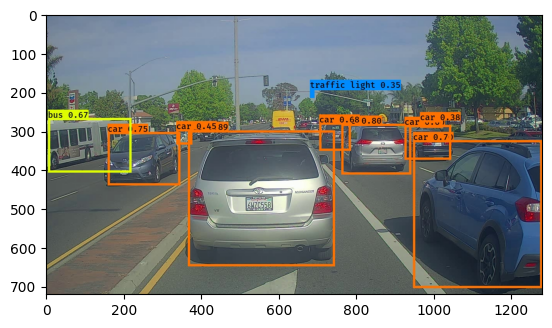

In [28]:
out_scores, out_boxes, out_classes = predict("test.jpg")

**Expected Output**:

<table>
    <tr>
        <td>
            <b>Found 10 boxes for images/test.jpg</b>
        </td>
    </tr>
    <tr>
        <td>
            <b>car</b>
        </td>
        <td>
           0.89 (367, 300) (745, 648)
        </td>
    </tr>
    <tr>
        <td>
            <b>car</b>
        </td>
        <td>
           0.80 (761, 282) (942, 412)
        </td>
    </tr>
    <tr>
        <td>
            <b>car</b>
        </td>
        <td>
           0.74 (159, 303) (346, 440)
        </td>
    </tr>
    <tr>
        <td>
            <b>car</b>
        </td>
        <td>
          0.70 (947, 324) (1280, 705)
        </td>
    </tr>
    <tr>
        <td>
            <b>bus</b>
        </td>
        <td>
           0.67 (5, 266) (220, 407)
        </td>
    </tr>
    <tr>
        <td>
            <b>car</b>
        </td>
        <td>
           0.66 (706, 279) (786, 350)
        </td>
    </tr>
    <tr>
        <td>
            <b>car</b>
        </td>
        <td>
           0.60 (925, 285) (1045, 374)
        </td>
    </tr>
        <tr>
        <td>
            <b>car</b>
        </td>
        <td>
           0.44 (336, 296) (378, 335)
        </td>
    </tr>
    <tr>
        <td>
            <b>car</b>
        </td>
        <td>
           0.37 (965, 273) (1022, 292)
        </td>
    </tr>
    <tr>
        <td>
            <b>traffic light</b>
        </td>
        <td>
           00.36 (681, 195) (692, 214)
        </td>
    </tr>
</table>

Mô hình mà bạn vừa chạy thực tế có khả năng nhận diện 80 lớp (loại đối tượng) khác nhau được liệt kê trong tệp "coco_classes.txt". Để kiểm thử mô hình với hình ảnh của riêng bạn:
1. Nhấp vào "File" trên thanh công cụ phía trên của notebook này, sau đó chọn "Open" để truy cập Coursera Hub. 
2. Thêm hình ảnh của bạn vào thư mục "images" nằm trong thư mục gốc của Jupyter Notebook này.
3. Nhập tên hình ảnh của bạn vào ô (cell) nằm ngay phía trên đoạn mã. 
4. Chạy đoạn mã và xem kết quả đầu ra của thuật toán!

Nếu bạn thực hiện chạy phiên làm việc (session) trong một vòng lặp `for` để xử lý tất cả các hình ảnh của mình, kết quả thu được sẽ như sau:

<center>
<video width="400" height="200" src="nb_images/pred_video_compressed2.mp4" type="video/mp4" controls>
</video>
</center>

<caption><center> Kết quả dự đoán của mô hình YOLO trên các hình ảnh được ghi lại từ camera khi lái xe quanh khu vực Thung lũng Silicon (Silicon Valley) <br> Xin cảm ơn <a href="https://www.drive.ai/">drive.ai</a> đã cung cấp bộ dữ liệu này! </center></caption>

<a name='4'></a>
## 4 - Tóm tắt về YOLO

- Ảnh đầu vào có kích thước (608, 608, 3)
- Ảnh đầu vào đi qua một mạng CNN, tạo ra đầu ra có kích thước (19, 19, 5, 85).
- Sau khi làm phẳng (flatten) hai chiều cuối cùng, đầu ra là một khối dữ liệu có hình dạng (19, 19, 425):
- Mỗi ô trong lưới 19x19 trên ảnh đầu vào cung cấp 425 giá trị. 
- 425 = 5 x 85 vì mỗi ô chứa các dự đoán cho 5 khung hình (box), tương ứng với 5 khung neo (anchor box) như đã đề cập trong bài giảng. 
- 85 = 5 + 80, trong đó số 5 xuất phát từ việc bộ tham số $(p_c, b_x, b_y, b_h, b_w)$ gồm 5 giá trị, còn 80 là số lượng lớp (class) cần phát hiện.
- Sau đó, bạn chọn ra một số ít khung hình dựa trên:
- Ngưỡng điểm số (Score-thresholding): loại bỏ các khung hình có điểm số dự đoán lớp thấp hơn ngưỡng quy định.
- Loại bỏ các khung hình không phải cực đại (Non-max suppression): tính toán chỉ số IoU (Intersection over Union - phần giao chia cho phần hợp) và tránh chọn các khung hình chồng lấn lên nhau.
- Quy trình này mang lại kết quả đầu ra cuối cùng của YOLO.